<center><h1>Kavle_Anirudh_HW5</h1></center>
<br>
<br>

Name: Anirudh Kavle
<br>
Github Username: Anirudh-Kavle
<br>
Email: kavle@usc.edu
<br>
USC ID: 6327-5359-63

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import StratifiedKFold, KFold, GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

### (a) Obtain Data

`diagnosis.data` is UTF-16 encoded, tab-separated, and uses commas for decimals, so `read_csv` needs all three options. The yes/no columns are then converted to 1/0.

In [2]:
cols = ["temp", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains",
        "burning_urethra", "bladder", "nephritis"]
acute = pd.read_csv("../data/acute_inflammations/diagnosis.data", sep="\t", header=None,
                    names=cols, decimal=",", encoding="utf-16")
acute[cols[1:]] = (acute[cols[1:]] == "yes").astype(int)
print(acute.shape)
acute.head()

(120, 8)


,temp,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

Label powerset turns the two labels (bladder inflammation and nephritis) into one class with 4 values, so a single tree can be fit. To answer the footnote: yes, it makes sense here. Only 4 label combinations exist, and each leaf ends up giving both diagnoses at once.

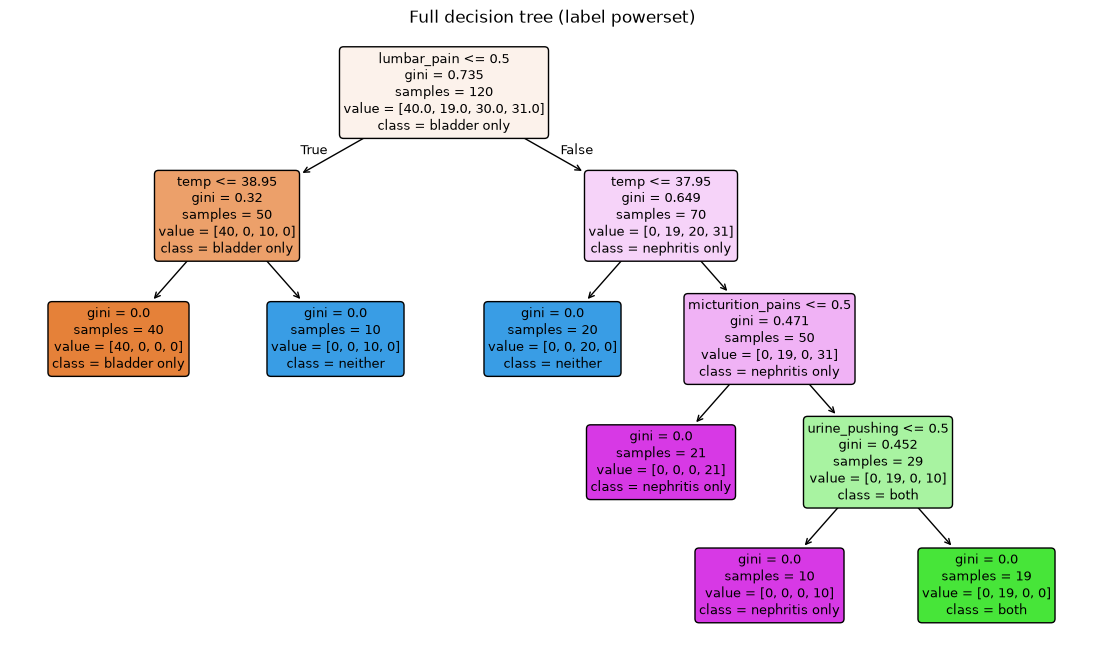

In [3]:
X1 = acute[cols[:6]]
combos = {(0, 0): "neither", (1, 0): "bladder only", (0, 1): "nephritis only", (1, 1): "both"}
y1 = pd.Series([combos[pair] for pair in zip(acute.bladder, acute.nephritis)])
tree = DecisionTreeClassifier(random_state=0).fit(X1, y1)

plt.figure(figsize=(14, 8))
plot_tree(tree, feature_names=list(X1.columns), class_names=list(tree.classes_), filled=True, rounded=True)
plt.title("Full decision tree (label powerset)")
plt.show()

### (c) Convert the decision rules

Each root-to-leaf path in the tree from (b) becomes one IF-THEN rule. The function is adapted from the KDnuggets code linked in the task.

In [4]:
def tree_to_rules(clf, feature_names):
    t = clf.tree_

    def recurse(node, conditions):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name, threshold = feature_names[t.feature[node]], t.threshold[node]
            if name == "temp":
                left, right = f"temp <= {threshold:.2f}", f"temp > {threshold:.2f}"
            else:  # yes/no symptom coded 1/0, split at 0.5
                left, right = f"{name} = no", f"{name} = yes"
            recurse(t.children_left[node], conditions + [left])
            recurse(t.children_right[node], conditions + [right])
        else:
            label = clf.classes_[t.value[node][0].argmax()]
            print(f"IF {' AND '.join(conditions)} THEN {label}")

    recurse(0, [])

tree_to_rules(tree, list(X1.columns))

IF lumbar_pain = no AND temp <= 38.95 THEN bladder only
IF lumbar_pain = no AND temp > 38.95 THEN neither
IF lumbar_pain = yes AND temp <= 37.95 THEN neither
IF lumbar_pain = yes AND temp > 37.95 AND micturition_pains = no THEN nephritis only
IF lumbar_pain = yes AND temp > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis only
IF lumbar_pain = yes AND temp > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both


### (d) Cost-complexity pruning

In [5]:
path = tree.cost_complexity_pruning_path(X1, y1)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
rows = []
for a in path.ccp_alphas:
    pruned = DecisionTreeClassifier(random_state=0, ccp_alpha=a).fit(X1, y1)
    cv_acc = cross_val_score(pruned, X1, y1, cv=cv5).mean()
    rows.append([a, pruned.get_n_leaves(), pruned.score(X1, y1), cv_acc])
pd.DataFrame(rows, columns=["ccp_alpha", "leaves", "training accuracy", "5-fold CV accuracy"]).round(3)

,ccp_alpha,leaves,training accuracy,5-fold CV accuracy
0,0.000,6,1.000,0.992
1,0.098,4,0.842,0.858
2,0.133,3,0.758,0.758
3,0.182,2,0.592,0.683
4,0.223,1,0.333,0.483


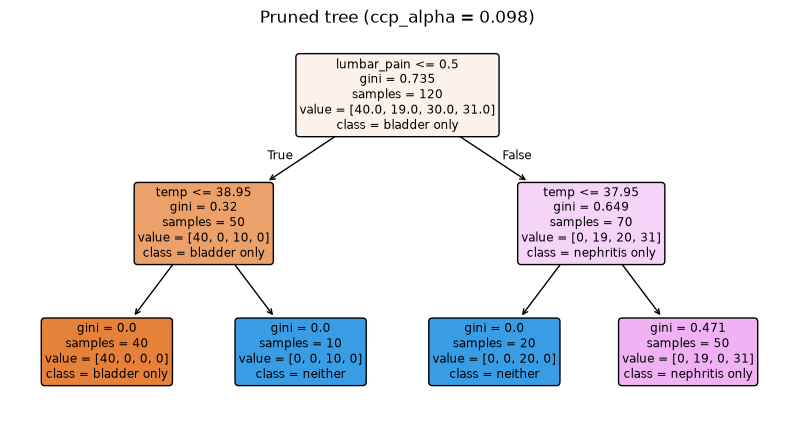

IF lumbar_pain = no AND temp <= 38.95 THEN bladder only
IF lumbar_pain = no AND temp > 38.95 THEN neither
IF lumbar_pain = yes AND temp <= 37.95 THEN neither
IF lumbar_pain = yes AND temp > 37.95 THEN nephritis only


In [6]:
pruned = DecisionTreeClassifier(random_state=0, ccp_alpha=path.ccp_alphas[1]).fit(X1, y1)

plt.figure(figsize=(10, 5))
plot_tree(pruned, feature_names=list(X1.columns), class_names=list(pruned.classes_), filled=True, rounded=True)
plt.title(f"Pruned tree (ccp_alpha = {path.ccp_alphas[1]:.3f})")
plt.show()

tree_to_rules(pruned, list(X1.columns))

Cross-validation selects ccp_alpha = 0: the unpruned 6-leaf tree has the highest 5-fold CV accuracy (0.992), so it is already the smallest tree on the pruning path that classifies every case correctly. Its 6 rules from (c) are the final rule set.

The next step, ccp_alpha = 0.098, gives a 4-leaf tree that is easier to read, but training accuracy falls to 0.842 and CV accuracy to 0.858, because none of its rules predicts "both" (all 19 cases with both diseases become "nephritis only").

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [7]:
names = [line.split()[1] for line in open("../data/communities_crime/communities.names")
         if line.startswith("@attribute")]
crime = pd.read_csv("../data/communities_crime/communities.data", header=None, names=names, na_values="?")
train, test = crime.iloc[:1495], crime.iloc[1495:]
print(crime.shape, train.shape, test.shape)

(1994, 128) (1495, 128) (499, 128)


### (b) Missing values

I dropped the 5 columns the data description calls non-predictive (state, county, community, communityname, fold). Missing values are filled with each column's median, computed on the training rows only.

In [8]:
drop = ["state", "county", "community", "communityname", "fold", "ViolentCrimesPerPop"]
X_train, X_test = train.drop(columns=drop), test.drop(columns=drop)
y_train, y_test = train["ViolentCrimesPerPop"], test["ViolentCrimesPerPop"]

X_all = crime.drop(columns=drop)
missing = X_all.isna().sum()
print(missing[missing > 0])

imputer = SimpleImputer(strategy="median").set_output(transform="pandas").fit(X_train)
X_train_imp, X_test_imp = imputer.transform(X_train), imputer.transform(X_test)

OtherPerCap                1
LemasSwornFT            1675
LemasSwFTPerPop         1675
LemasSwFTFieldOps       1675
LemasSwFTFieldPerPop    1675
LemasTotalReq           1675
LemasTotReqPerPop       1675
PolicReqPerOffic        1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
OfficAssgnDrugUnits     1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PolicCars               1675
PolicOperBudg           1675
LemasPctPolicOnPatr     1675
LemasGangUnitDeploy     1675
PolicBudgPerPop         1675
dtype: int64


### (c) Plot a correlation matrix

Parts (c) to (e) use all 1,994 rows. pandas skips the missing values when computing these.

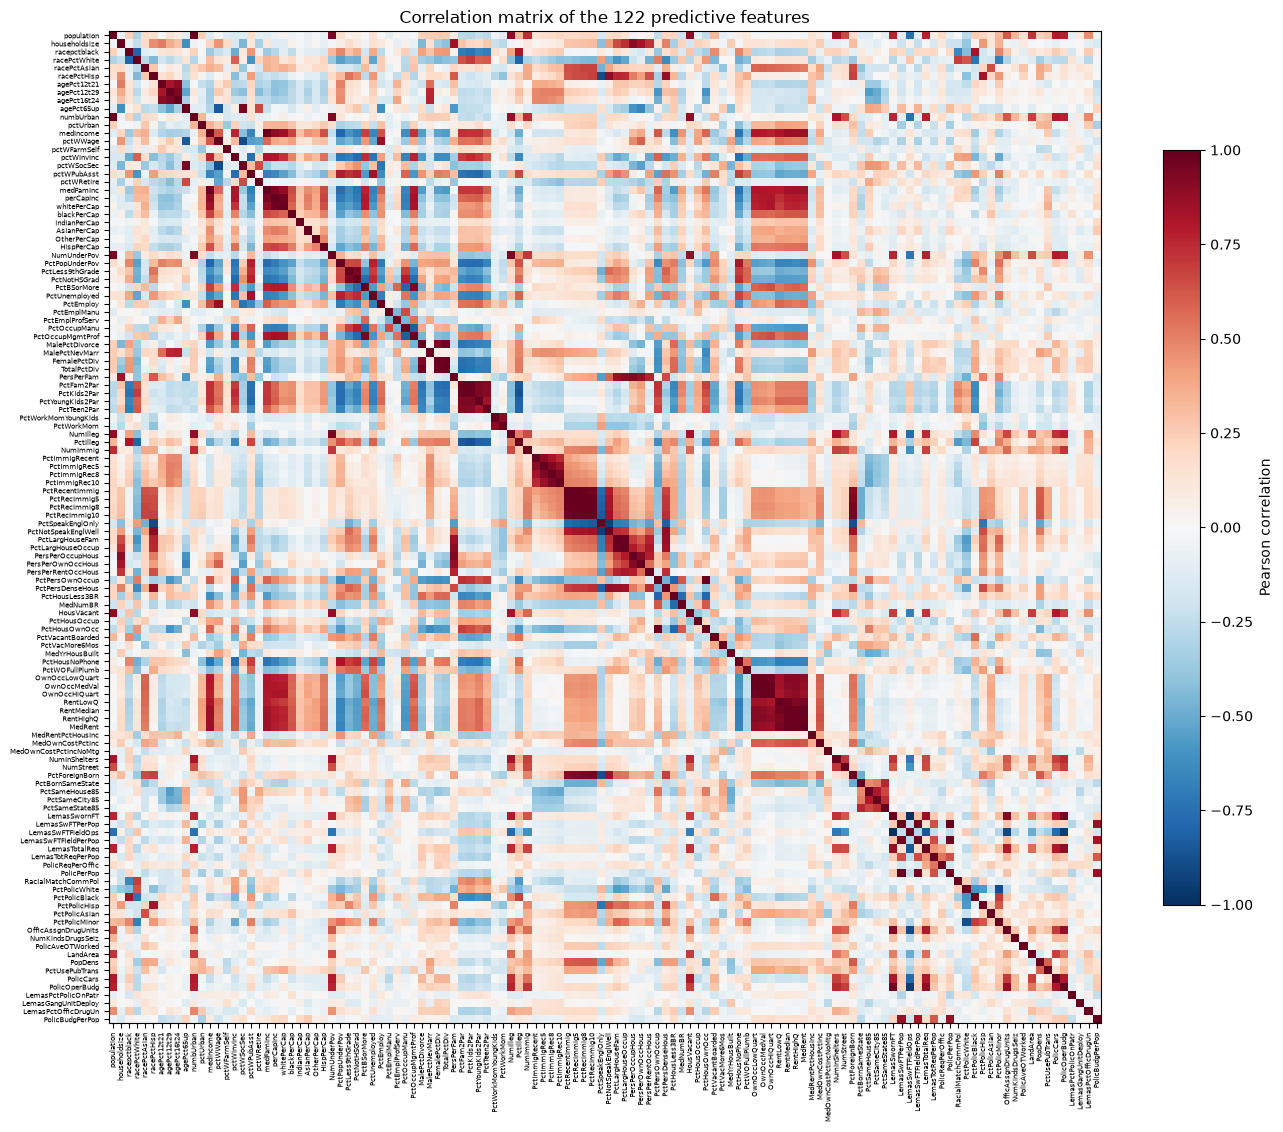

In [9]:
corr = X_all.corr()

fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=5)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=5)
fig.colorbar(im, ax=ax, shrink=0.7, label="Pearson correlation")
ax.set_title("Correlation matrix of the 122 predictive features")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [10]:
cv = (X_all.std() / X_all.mean()).sort_values(ascending=False)  # pandas std is the sample sd (ddof=1)
print(cv.round(3).to_string())

NumStreet                4.408
NumInShelters            3.485
NumIlleg                 2.994
NumImmig                 2.900
LemasPctOfficDrugUn      2.555
NumUnderPov              2.305
population               2.204
numbUrban                2.002
LemasSwornFT             1.985
PctPolicAsian            1.979
HousVacant               1.959
PolicOperBudg            1.828
LandArea                 1.678
LemasTotalReq            1.652
racePctHisp              1.614
OfficAssgnDrugUnits      1.590
PctNotSpeakEnglWell      1.459
PctPolicHisp             1.455
PctUsePubTrans           1.417
racepctblack             1.411
racePctAsian             1.359
PolicCars                1.317
PctRecentImmig           1.300
PctRecImmig5             1.298
PctRecImmig10            1.284
PctRecImmig8             1.281
PctPersDenseHous         1.127
PctForeignBorn           1.072
PctPolicBlack            1.072
PctVacantBoarded         1.065
LemasGangUnitDeploy      0.921
PctIlleg                 0.920
PctHousN

### (e) Scatter plots and box plots for highest CV features

11 ['NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'numbUrban', 'LemasSwornFT', 'PctPolicAsian', 'HousVacant']


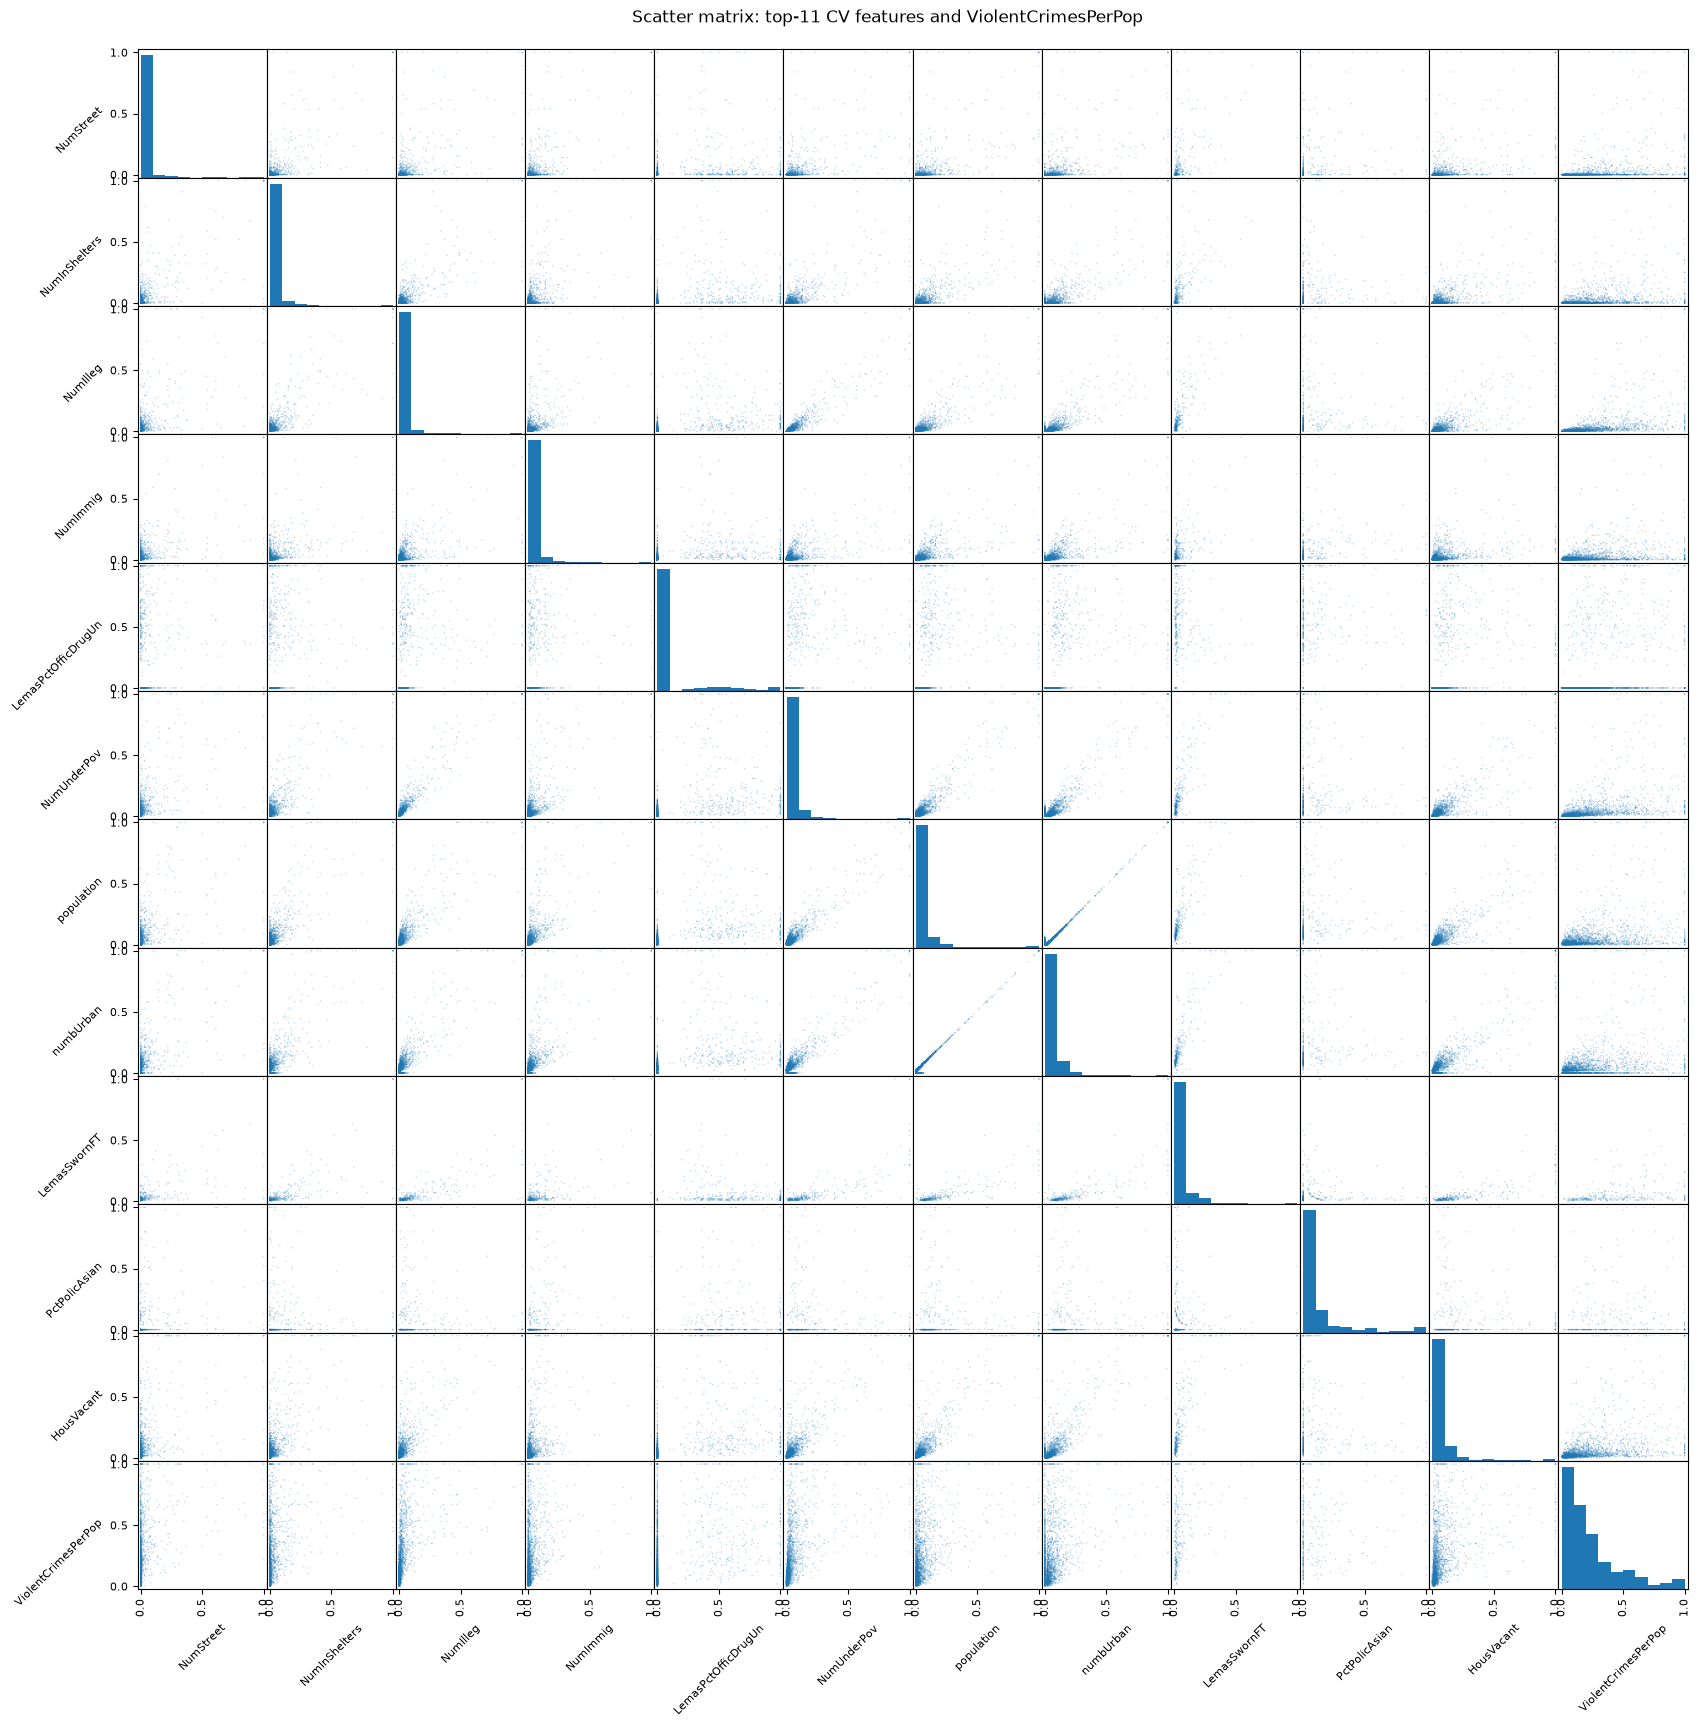

In [11]:
k = math.isqrt(128)
top = list(cv.index[:k])
print(k, top)

axes = pd.plotting.scatter_matrix(X_all[top].join(crime["ViolentCrimesPerPop"]),
                                  figsize=(20, 20), s=4, alpha=0.3)
for ax in axes.ravel():
    ax.xaxis.label.set(rotation=45, fontsize=8)
    ax.yaxis.label.set(rotation=45, fontsize=8, ha="right")
plt.suptitle("Scatter matrix: top-11 CV features and ViolentCrimesPerPop", y=0.9)
plt.show()

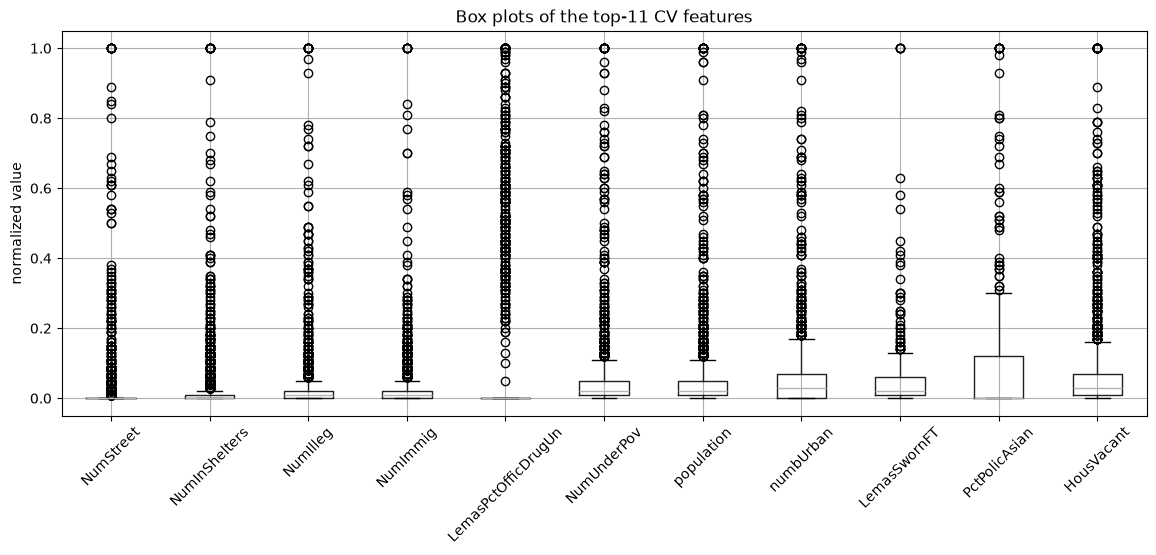

In [12]:
X_all[top].boxplot(figsize=(14, 5), rot=45)
plt.ylabel("normalized value")
plt.title("Box plots of the top-11 CV features")
plt.show()

No. In every plot most of the points are bunched up near 0. In the bottom row, the crime rate goes from low to high over roughly the same small feature values, with at most a slight upward trend.

A scatter plot only looks at one feature at a time and doesn't give any test, so it can't tell us whether a feature is significant. That needs a fitted model and a statistical test.

### (f) Fit a linear model

In [13]:
ols = LinearRegression().fit(X_train_imp, y_train)
print("OLS test MSE:", round(mean_squared_error(y_test, ols.predict(X_test_imp)), 5))

OLS test MSE: 0.01797


### (g) Fit a ridge regression model

In [14]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)

ridge = RidgeCV(alphas=np.logspace(-3, 3, 61), cv=kf, scoring="neg_mean_squared_error").fit(X_train_imp, y_train)
print("lambda chosen by 10-fold CV:", round(ridge.alpha_, 4))
print("Ridge test MSE:", round(mean_squared_error(y_test, ridge.predict(X_test_imp)), 5))

lambda chosen by 10-fold CV: 3.1623
Ridge test MSE: 0.01748


### (h) Fit a LASSO model

In [15]:
scaler = StandardScaler().fit(X_train_imp)
for name, Xtr, Xte in [("raw", X_train_imp, X_test_imp),
                       ("standardized", scaler.transform(X_train_imp), scaler.transform(X_test_imp))]:
    lasso = LassoCV(cv=kf, max_iter=100000).fit(Xtr, y_train)
    selected = X_train.columns[lasso.coef_ != 0]
    print(f"{name}: lambda = {lasso.alpha_:.3g}, test MSE = {mean_squared_error(y_test, lasso.predict(Xte)):.5f}, "
          f"{len(selected)} variables selected:")
    print(", ".join(selected), "\n")

raw: lambda = 0.000125, test MSE = 0.01762, 74 variables selected:
racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctBornSameState, PctSameCity85, LemasSwFTFieldPerPop, PolicReqPerOffic, RacialMatchCommPol, PctPolicBlac

standardized: lambda = 0.000664, test MSE = 0.01771, 75 variables selected:
racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctSameCity85, LemasSwFTFieldPerPop, LemasTotalReq, PolicReqPerOffic, RacialMatchCommPol, PctPol

The two versions barely differ. Test MSE is 0.01762 with the raw features and 0.01771 with the standardized ones, and the selected lists differ in only three variables. That makes sense, since the features were already normalized (footnote 4).

### (i) Fit a PCR model

In [16]:
pcr = GridSearchCV(make_pipeline(StandardScaler(), PCA(), LinearRegression()),
                   {"pca__n_components": range(1, X_train.shape[1] + 1)},
                   cv=kf, scoring="neg_mean_squared_error").fit(X_train_imp, y_train)
print("M chosen by 10-fold CV:", pcr.best_params_["pca__n_components"])
print("PCR test MSE:", round(mean_squared_error(y_test, pcr.predict(X_test_imp)), 5))

M chosen by 10-fold CV: 95
PCR test MSE: 0.0183


### (j) Fit a boosting tree

α is XGBoost's L1 regularization term (`reg_alpha`), chosen by 10-fold CV.

In [17]:
xgb = GridSearchCV(XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=3, n_jobs=1),
                   {"reg_alpha": np.r_[0, np.logspace(-3, 1.5, 19)]},
                   cv=kf, scoring="neg_mean_squared_error", n_jobs=-1).fit(X_train_imp, y_train)
print("alpha chosen by 10-fold CV:", round(xgb.best_params_["reg_alpha"], 5))
print("XGBoost test MSE:", round(mean_squared_error(y_test, xgb.predict(X_test_imp)), 5))

alpha chosen by 10-fold CV: 0.56234
XGBoost test MSE: 0.01663


*AI use: Claude Code (Anthropic) was used to edit this notebook from my own script and notes*